<a href="https://colab.research.google.com/github/Business-Intelligence-Book/business-intelligence-book.github.io/blob/main/labs/04-clustering/walkthrough/walkthrough.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<h1 style="color:#2F5597"><span style="background:#2F5597;color:#fff;padding:2px 10px;border-radius:3px">Lab 04</span>&nbsp; Clustering</h1>

<p style="color:#595959"><b style="color:#C55A11">Walkthrough</b> · Clustering · <i>Business Intelligence and Analytics</i> · Chapter 5</p>

<div style="background:#FFF2CC;border-radius:10px;padding:14px 20px;margin:12px 0;color:#222">
<p style="margin:0 0 6px 0"><b style="color:#C55A11">💡 What you will learn this week</b></p>
<ul style="margin:0">
<li>What clustering is and when it is useful: finding groups in unlabeled data</li>
<li>How k-means works, and how to choose <i>k</i> with the elbow method</li>
<li>How hierarchical clustering works, and how to read a dendrogram</li>
<li>How to visualize and interpret the clusters you find</li>
</ul>
</div>

Run the cells from top to bottom. Text cells explain each step; code cells show how to do it in Python.

---

![clustering image](https://static.javatpoint.com/tutorial/machine-learning/images/k-means-clustering-algorithm-in-machine-learning.png)

### Clustering
Clustering divides data points into groups, so that the points in the same group are more similar to each other than to the points in other groups. In simple words, the aim is to group similar data points together.

### K-means clustering
K-means is one of the simplest and most popular unsupervised machine learning algorithms. You choose a number k, the number of clusters you want. Each cluster is represented by its centroid, the point at the center of the cluster.

The algorithm assigns each data point to the nearest centroid, then updates each centroid as the average of the points assigned to it. It repeats these two steps until the centroids no longer move, or until a stopping condition is met. In doing so, it minimizes the within-cluster sum of squares. The "means" in k-means refers to the averaging step.

### About the dataset
In this walkthrough, you work with a dataset of the customers of a mall: their ID, age, gender, annual income and spending score. The spending score is assigned to each customer by the mall, based on purchasing behavior.

### An application of k-means clustering
K-means can be used, for example, to find the best place to open a new bakery in a city.

<div style="background:#E8EEF7;border-radius:10px;padding:14px 20px;margin:12px 0;color:#222">
<p style="margin:0 0 6px 0"><b style="color:#2F5597">⭐ Fun fact: An algorithm that waited 25 years to be published</b></p>
Stuart Lloyd devised the standard k-means algorithm at Bell Labs in 1957, to digitize telephone signals. It remained an internal report until it was finally published in a journal in 1982. In the meantime, James MacQueen had given the method its name, <i>k-means</i>, in 1967.
</div>

## K-means clustering

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("darkgrid")

import plotly as py
import plotly.graph_objs as go

from sklearn.cluster import KMeans

import warnings

warnings.filterwarnings("ignore")

## Data exploration

In [2]:
df = pd.read_csv(
    "https://raw.githubusercontent.com/Business-Intelligence-Book/business-intelligence-book.github.io/main/labs/data/mall_customers.csv",
    index_col="CustomerID",
)
df.head()

,Gender,Age,Annual Income (k$),Spending Score (1-100)
CustomerID,,,,
1,Male,19,15,39
2,Male,21,15,81
3,Female,20,16,6
4,Female,23,16,77
5,Female,31,17,40


In [3]:
df.columns

Index(['Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)'], dtype='object')

In [4]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
Index: 200 entries, 1 to 200
Data columns (total 4 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   Gender                  200 non-null    object
 1   Age                     200 non-null    int64 
 2   Annual Income (k$)      200 non-null    int64 
 3   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(3), object(1)
memory usage: 7.8+ KB
None


In [5]:
df.describe()

,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000
mean,38.850000,60.560000,50.200000
std,13.969007,26.264721,25.823522
min,18.000000,15.000000,1.000000
25%,28.750000,41.500000,34.750000
50%,36.000000,61.500000,50.000000
75%,49.000000,78.000000,73.000000
max,70.000000,137.000000,99.000000


### Checking for null values

In [6]:
df.isnull().sum()

Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

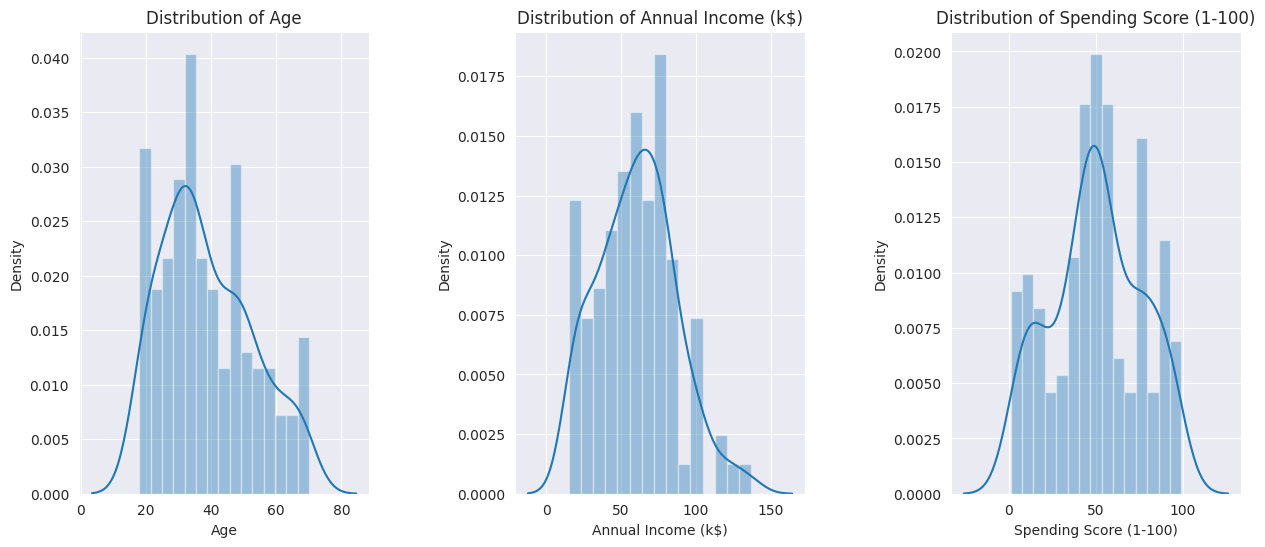

In [7]:
# See the distribution of the values for the numerical columns of the dataset.
plt.figure(1, figsize=(15, 6))
n = 0

# Plot each column of the dataframe in a separate subplot
for x in ["Age", "Annual Income (k$)", "Spending Score (1-100)"]:
    n += 1
    plt.subplot(1, 3, n)
    plt.subplots_adjust(hspace=0.5, wspace=0.5)
    sns.distplot(df[x], bins=15)
    plt.title("Distribution of {}".format(x))
plt.show()

Next, let's look at the pair plot of the numerical columns. A pair plot shows the distribution of each variable (on the diagonal) and the relationship between each pair of variables. We can also color the points by a categorical variable, here the column `Gender`.

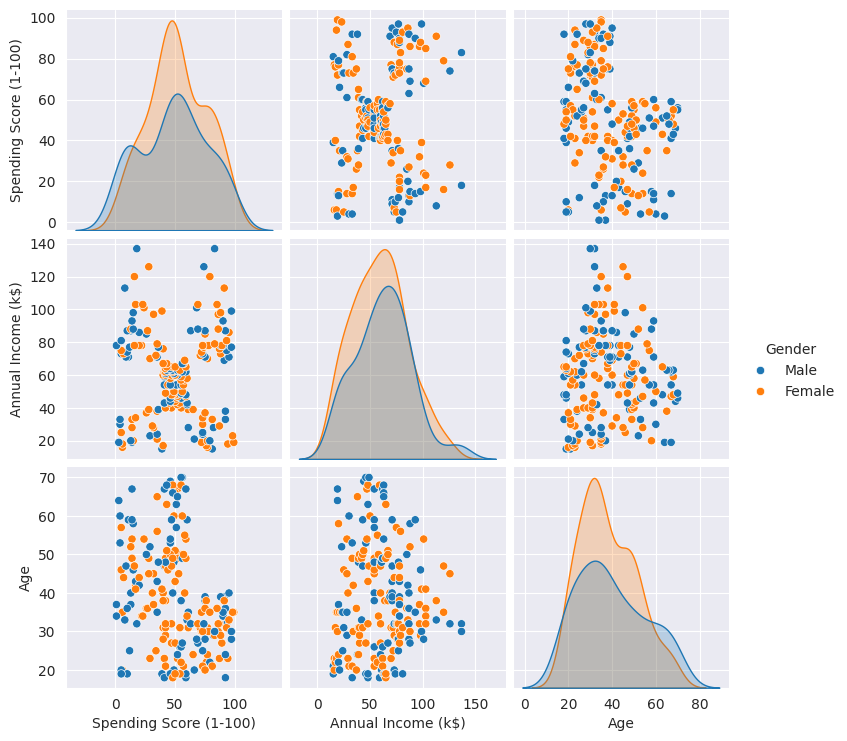

In [8]:
sns.pairplot(
    df, vars=["Spending Score (1-100)", "Annual Income (k$)", "Age"], hue="Gender"
)

## 2D clustering based on age and spending score

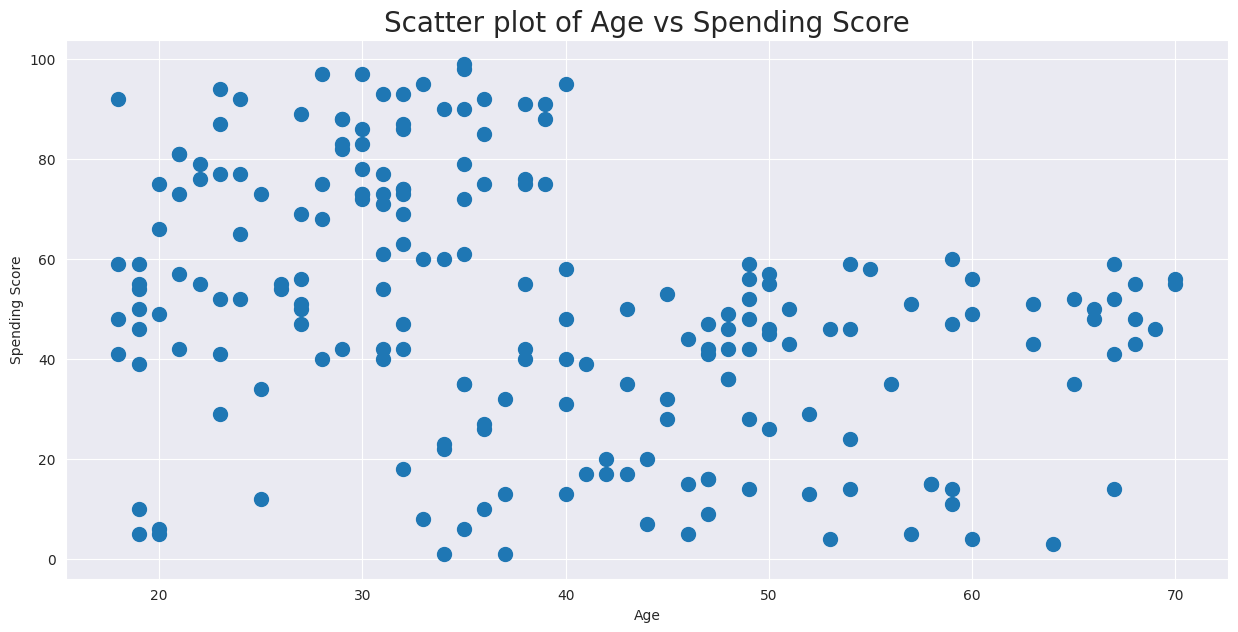

In [9]:
# Scatter plot of Age vs Spending Score without any clustering
plt.figure(1, figsize=(15, 7))
plt.title("Scatter plot of Age vs Spending Score", fontsize=20)
plt.xlabel("Age")
plt.ylabel("Spending Score")
plt.scatter(x="Age", y="Spending Score (1-100)", data=df, s=100)
plt.show()

#### Choosing the value of k

We use the elbow method to find a good number of clusters:
- Run k-means for several numbers of clusters and compute the inertia each time (the sum of squared distances of the points to their closest cluster center).
- The best number of clusters is at the "elbow": **the point after which the inertia decreases only slowly, in a roughly linear fashion**.

In real-world datasets, the elbow is not always clear, and several values of k can be equally plausible.

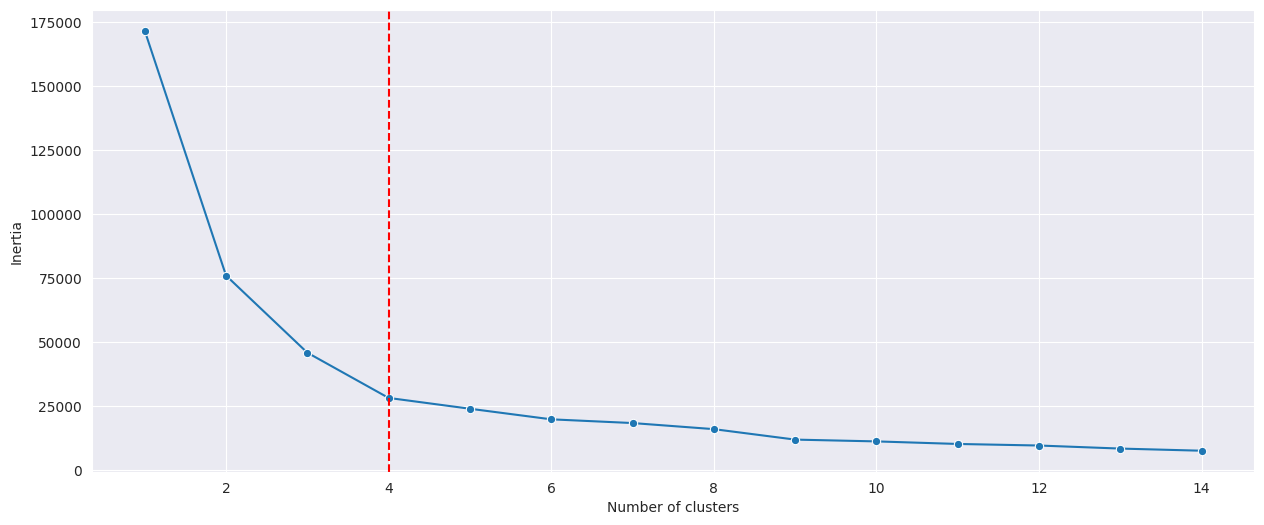

In [10]:
# Elbow method to find the optimal number of clusters
X_2D = df[["Age", "Spending Score (1-100)"]].values
inertia = []
NB_ITER = 15
for n in range(1, NB_ITER):
    algorithm = KMeans(n_clusters=n, random_state=111)
    algorithm.fit(X_2D)
    inertia.append(algorithm.inertia_)

# Plot vertical line at the point of maximum curvature
plt.figure(1, figsize=(15, 6))
sns.lineplot(x=np.arange(1, NB_ITER), y=inertia, sort=False, marker="o")
plt.xlabel("Number of clusters"), plt.ylabel("Inertia")
plt.axvline(x=4, color="r", linestyle="--")  # We plot manually the red line on x=4
plt.show()

In the elbow plot, the best number of clusters appears to be 4, so we use this value in the next section.

In [11]:
algorithm = KMeans(n_clusters=4, random_state=111)
algorithm.fit(X_2D)
labels1 = algorithm.labels_
centroids1 = algorithm.cluster_centers_

Now let's look at the cluster centroids and at the cluster of each data point. The `labels_` attribute of `KMeans` gives the index of the cluster assigned to each data point. The `cluster_centers_` attribute gives the coordinates of each cluster center.

In [12]:
# The labels are the cluster indices assigned to each data point
print(labels1)

[0 2 1 2 0 2 1 2 1 2 1 2 1 2 1 2 0 0 1 2 0 2 1 2 1 2 1 0 1 2 1 2 1 2 1 2 1
 2 1 2 3 2 3 0 1 0 3 0 0 0 3 0 0 3 3 3 3 3 0 3 3 0 3 3 3 0 3 3 0 0 3 3 3 3
 3 0 3 0 0 3 3 0 3 3 0 3 3 0 0 3 3 0 3 0 0 0 3 0 3 0 0 3 3 0 3 0 3 3 3 3 3
 0 0 0 0 0 3 3 3 3 0 0 0 2 0 2 3 2 1 2 1 2 0 2 1 2 1 2 1 2 1 2 0 2 1 2 3 2
 1 2 1 2 1 2 1 2 1 2 1 2 3 2 1 2 1 2 1 2 1 0 1 2 1 2 1 2 1 2 1 2 1 2 1 2 3
 2 1 2 1 2 1 2 1 2 1 2 1 2 1 2]


In [13]:
# Print the centroids coordinates. The first row indicates the coordinates of
# the centroid of cluster 0, the second row indicates the coordinates of the
# centroid of cluster 1, and so on.
print(centroids1)

[[27.32608696 49.36956522]
 [43.29166667 15.02083333]
 [30.1754386  82.35087719]
 [55.40816327 48.04081633]]


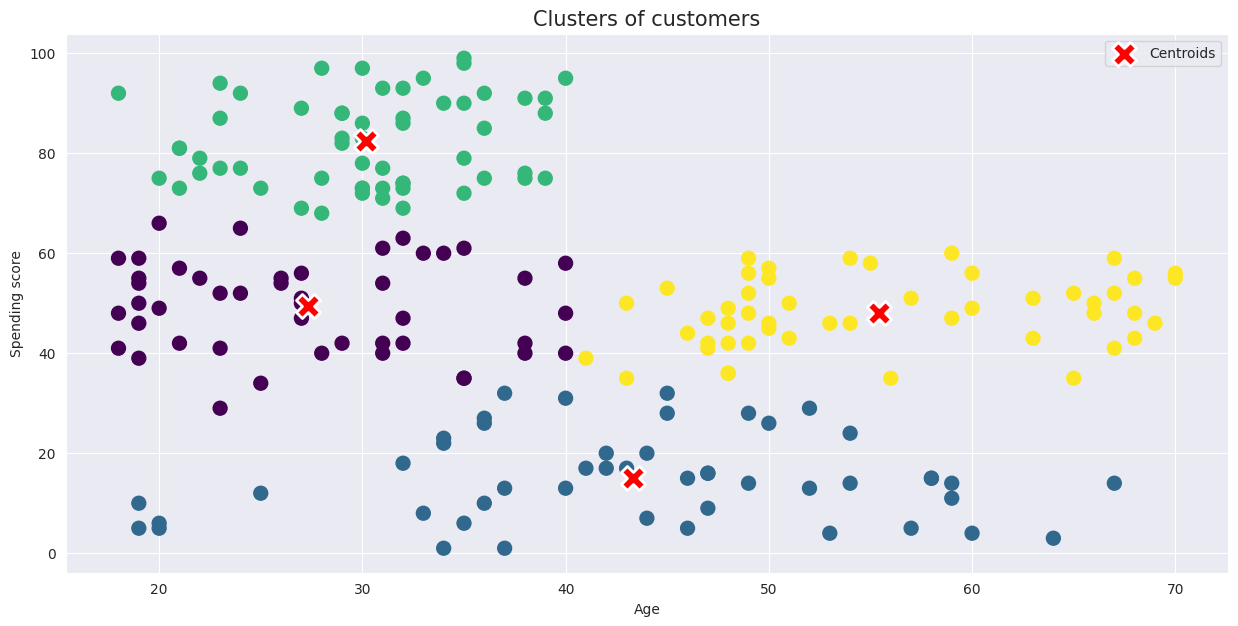

In [14]:
# Create a scatter plot of the data colored by the cluster labels
plt.figure(figsize=(15, 7))

# Scatter plot for data points with distinct colors for each cluster
plt.scatter(df["Age"], df["Spending Score (1-100)"], s=100, c=labels1, cmap="viridis")

# Scatter plot for centroids with a distinct color and marker
plt.scatter(
    centroids1[:, 0],
    centroids1[:, 1],
    s=300,
    c="red",
    marker="X",
    edgecolors="white",
    linewidth=2,
    label="Centroids",
)

plt.title("Clusters of customers", fontsize=15)
plt.xlabel("Age")
plt.ylabel("Spending score")
plt.legend()
plt.show()

In [15]:
# This code creates a mesh grid of the data points found in X_2D[:, 0] and X_2D[:, 1]
# with a step size of h (in this case 0.02).
# The mesh grid is then used to predict the output of the algorithm for each point on the grid.
# The result is stored in the Z variable.

h = 0.02

# Get the minimum and maximum values of the data
# +/- 1 to be sure that the mesh grid covers all the data points
x_min, x_max = X_2D[:, 0].min() - 1, X_2D[:, 0].max() + 1
y_min, y_max = X_2D[:, 1].min() - 1, X_2D[:, 1].max() + 1

# Create a mesh grid of all the points in the plot
xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))

# Use the predict method of the algorithm to predict the output for all the points
# in the mesh grid. So here the 'algorithm' is related to the k-means we did.
# We use it to predict the output for every point of the mesh grid according to the
# training we did. -> represented by the colors dividing the graph below
Z = algorithm.predict(np.c_[xx.ravel(), yy.ravel()])

# NOTE :
# np.c_ is a NumPy function used to concatenate two arrays along the second axis.
# It takes two arrays and returns an array combining them along the second axis.
# In this case, it combines the two arrays xx.ravel() and yy.ravel() along the
# second axis, which is the column axis.
# The result is an array of two columns, which is then used by the algorithm.predict()
# method to predict the output for each point on the mesh grid.

The plot below shows how the trained k-means model assigns new data points to one of the four clusters. Each colored region contains the points that are closest to the same centroid.

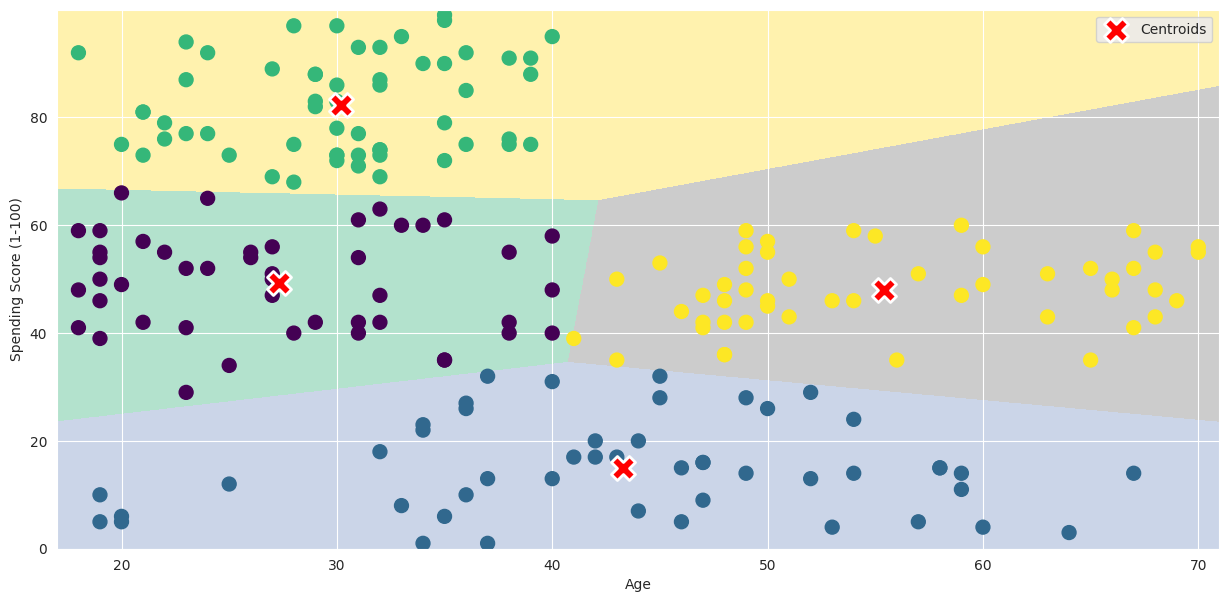

In [16]:
plt.figure(1, figsize=(15, 7))
plt.clf()
Z = Z.reshape(xx.shape)
plt.imshow(
    Z,
    interpolation="nearest",
    extent=(xx.min(), xx.max(), yy.min(), yy.max()),
    cmap=plt.cm.Pastel2,
    aspect="auto",
    origin="lower",
)

plt.scatter(df["Age"], df["Spending Score (1-100)"], s=100, c=labels1, cmap="viridis")
plt.scatter(
    centroids1[:, 0],
    centroids1[:, 1],
    s=300,
    c="red",
    marker="X",
    edgecolors="white",
    linewidth=2,
    label="Centroids",
)
plt.ylabel("Spending Score (1-100)"), plt.xlabel("Age")
plt.legend()
plt.show()

## 3D clustering based on age, annual income and spending score

The method generalizes to more than 2 dimensions. However, the result is harder to visualize in 3D and impossible to visualize in 4 or more dimensions.
Here we take the same example as before and add one more feature, the annual income.

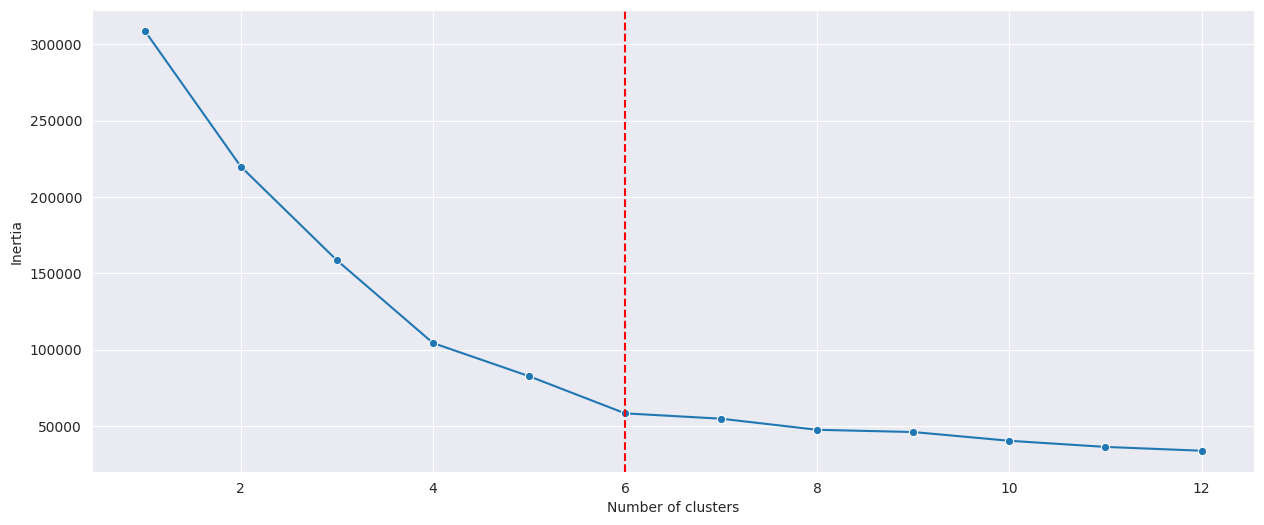

In [17]:
# Elbow method to find the optimal number of clusters
X_3D = df[["Age", "Annual Income (k$)", "Spending Score (1-100)"]].values
inertia = []
NB_ITER = 13
for n in range(1, NB_ITER):
    algorithm = KMeans(n_clusters=n, random_state=111)
    algorithm.fit(X_3D)
    inertia.append(algorithm.inertia_)

# Plot vertical line at the point of maximum curvature
plt.figure(1, figsize=(15, 6))
sns.lineplot(x=np.arange(1, NB_ITER), y=inertia, sort=False, marker="o")
plt.xlabel("Number of clusters"), plt.ylabel("Inertia")
plt.axvline(x=6, color="r", linestyle="--")
plt.show()

In [18]:
algorithm = KMeans(n_clusters=6, random_state=111)
algorithm.fit(X_3D)  # fit with the values
labels3 = algorithm.labels_
centroids3 = algorithm.cluster_centers_

y_kmeans = algorithm.fit_predict(X_3D)
# add a new column to the dataframe which indicates the cluster index assigned to each point.
df["cluster"] = pd.DataFrame(y_kmeans)
df.head()

,Gender,Age,Annual Income (k$),Spending Score (1-100),cluster
CustomerID,,,,,
1,Male,19,15,39,2.0
2,Male,21,15,81,4.0
3,Female,20,16,6,2.0
4,Female,23,16,77,4.0
5,Female,31,17,40,2.0


In [19]:
import plotly as py
import plotly.graph_objs as go

trace1 = go.Scatter3d(
    x=df["Age"],
    y=df["Spending Score (1-100)"],
    z=df["Annual Income (k$)"],
    mode="markers",
    marker=dict(
        color=df["cluster"],
        size=10,
        line=dict(color=df["cluster"], width=12),
        opacity=0.8,
    ),
)
data = [trace1]
layout = go.Layout(
    title="Clusters wrt Age, Income and Spending Scores",
    scene=dict(
        xaxis=dict(title="Age"),
        yaxis=dict(title="Spending Score"),
        zaxis=dict(title="Annual Income"),
    ),
)
fig = go.Figure(data=data, layout=layout)
py.offline.iplot(fig)

## Hierarchical clustering

Hierarchical clustering builds a hierarchy of clusters. It starts by treating each data point as a cluster of its own. Then it repeatedly merges the two closest clusters, until all the points are in a single cluster or a stopping criterion is met. The process can be shown as a dendrogram, a tree-like diagram of the sequence of merges and of the distance at which each merge occurred. The distance between two clusters can be measured in different ways, called linkage criteria: single linkage (minimum distance), complete linkage (maximum distance), average linkage, and Ward's method (minimum increase in variance).

Let's apply this to the spending score column of our dataset, to group the customers by the similarity of their spending scores.

In [20]:
X_2 = df[["Spending Score (1-100)"]]

#### Agglomerative clustering

In [21]:
from sklearn.cluster import AgglomerativeClustering

clustering = AgglomerativeClustering(
    n_clusters=4, metric="euclidean", linkage="complete"
)
clustering.fit(X_2)

AgglomerativeClustering(linkage='complete', n_clusters=4)

In [22]:
# Print the labels
clustering.labels_

array([2, 1, 0, 3, 2, 3, 0, 1, 0, 3, 0, 1, 0, 3, 0, 3, 0, 3, 0, 1, 0, 3,
       0, 3, 0, 1, 0, 2, 0, 1, 0, 3, 0, 1, 0, 1, 0, 3, 0, 3, 0, 1, 0, 2,
       0, 3, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1, 0, 3, 0, 1, 0, 3, 0, 3,
       0, 3, 0, 1, 0, 3, 0, 3, 0, 1, 2, 1, 0, 1, 0, 3, 0, 1, 0, 1, 0, 3,
       0, 1, 0, 3, 0, 3, 0, 1, 0, 1, 0, 3, 0, 1, 0, 3, 0, 3, 0, 1, 0, 1,
       0, 3, 0, 1, 0, 1, 0, 1, 2, 1, 0, 3, 0, 1, 0, 3, 0, 1, 0, 3, 0, 3,
       0, 1])

The plot below shows how the spending scores are grouped into clusters. Each color is a cluster: points of the same color are customers with similar spending scores.

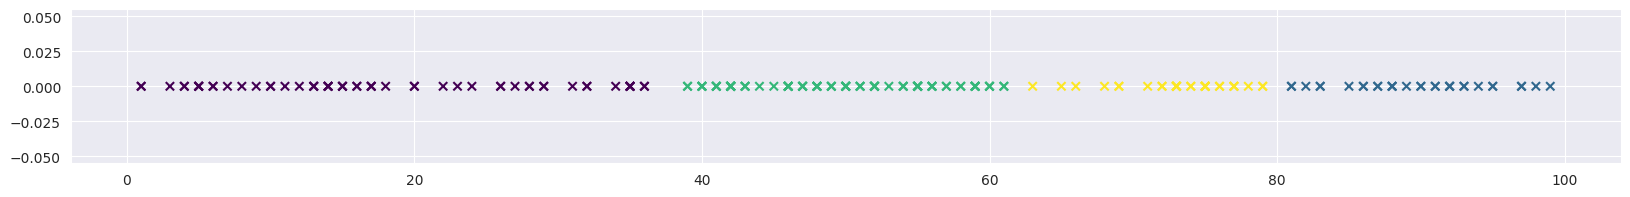

In [23]:
plt.figure(figsize=(20, 2))
plt.scatter(X_2, np.zeros_like(X_2), marker="x", c=clustering.labels_, cmap="viridis")

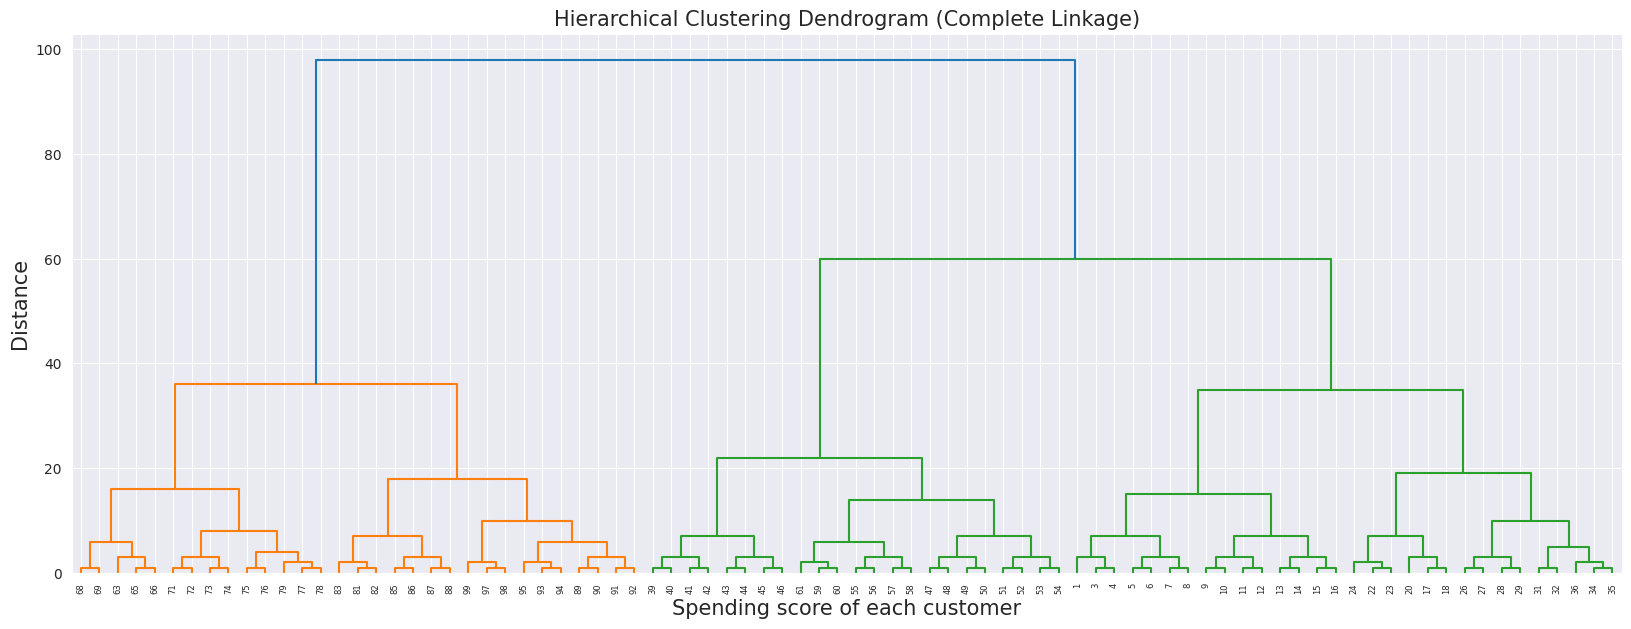

In [24]:
from scipy.cluster.hierarchy import dendrogram, linkage

plt.figure(figsize=(20, 7))
plt.title("Hierarchical Clustering Dendrogram (Complete Linkage)", fontsize=15)
plt.xlabel("Spending score of each customer", fontsize=15)
plt.ylabel("Distance", fontsize=15)

# To make the plot easier to read, let's only keep the unique spending score values.
X_2 = np.reshape(np.unique(X_2), (-1, 1))

# Provide the linkage method we want and the chosen distance metric.
W = linkage(X_2, method="complete", metric="euclidean")
dendrogram(W, labels=X_2.reshape(-1))  # compute the dendrogram according to the linkage

plt.show()